# Sesión 02 — Modelos de Clasificación
## Ejercicio 3 — Aplicación con dataset propio: clima de Bengaluru
**Curso:** Ingeniería del Conocimiento (ISO56B)
**Docente:** Msc. Jaime Antonio Huaytalla Pariona
**Periodo:** 2026-II | Universidad Nacional del Centro del Perú

---

## Objetivo
Aplicar y comparar los cuatro modelos de clasificación supervisada de la sesión — **Regresión Logística, Árbol de Decisión, SVM y KNN** — sobre un dataset propio: el **clima histórico de Bengaluru (India, 2009–2020)**, para predecir si un día es **lluvioso** a partir de sus condiciones atmosféricas.

> **Enunciado:** Seleccione un dataset de clasificación de su interés. Debe tener al menos 500 registros y 5 features. Aplique los 4 modelos de clasificación, realice el análisis comparativo completo y documente sus hallazgos.

## 1. Configuración del entorno

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay,
    accuracy_score, f1_score
)
from sklearn.inspection import DecisionBoundaryDisplay

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100

RANDOM_STATE = 42
print('Entorno configurado correctamente.')

Entorno configurado correctamente.


---
## 2. Carga y comprensión del dataset

Utilizamos el archivo **`bengaluru.csv`**: registros **horarios** del clima de Bengaluru desde el 01/01/2009 hasta el 01/01/2020 (96 432 filas, 25 columnas; sin valores nulos).

**¿Por qué se agrega por día?** Varias columnas son valores diarios repetidos en las 24 horas (`maxtempC`, `mintempC`, `sunHour`, `uvIndex`), por lo que las filas de un mismo día son casi idénticas. Con un split aleatorio por hora, casi-copias del mismo día quedarían en train y en test (fuga de información) y, además, SVM y KNN serían muy costosos con ~96 mil filas. Al agregar por día obtenemos **4018 registros independientes** (promedio diario de cada variable y precipitación total del día).

**Features seleccionadas (11):** `maxtempC`, `mintempC`, `sunHour`, `uvIndex`, `humidity`, `cloudcover`, `pressure`, `DewPointC`, `windspeedKmph`, `WindGustKmph`, `visibility`.
Se excluyen: `totalSnow_cm` (siempre 0), variables astronómicas (`moonrise`, `moonset`, `sunrise`, `sunset`, `moon_illumination`), variables derivadas de la temperatura (`FeelsLikeC`, `HeatIndexC`, `WindChillC`), `winddirDegree` (es un ángulo y su promedio no tiene sentido), el `uvIndex` horario duplicado y `precipMM`, que es la base de la variable objetivo (incluirla sería fuga de información).

Para construir un problema de **clasificación binaria**, definimos:
- **Clase 1 (Lluvioso):** precipitación total del día ≥ 1 mm
- **Clase 0 (Seco):** precipitación total del día < 1 mm

El umbral de 1 mm es el que se usa habitualmente en climatología para considerar un "día con lluvia". Esta binarización genera un **problema desbalanceado** (≈ 2.2 días secos por cada día lluvioso).

In [2]:
# Carga del archivo local (en Colab: subir 'bengaluru.csv' al panel de archivos antes de ejecutar)
df_raw = pd.read_csv('bengaluru.csv', parse_dates=['date_time'])
print(f'Dataset horario: {df_raw.shape[0]} registros, {df_raw.shape[1]} columnas')

# Agregación diaria: promedio de las variables atmosféricas y precipitación total del día
features_sel = ['maxtempC', 'mintempC', 'sunHour', 'uvIndex', 'humidity', 'cloudcover',
                'pressure', 'DewPointC', 'windspeedKmph', 'WindGustKmph', 'visibility']
df = (df_raw.groupby(df_raw['date_time'].dt.date)
            .agg({**{c: 'mean' for c in features_sel}, 'precipMM': 'sum'})
            .round(2))
df.index.name = 'fecha'
print(f'Dataset diario:  {df.shape[0]} registros, {df.shape[1]} columnas')
df.head()

Dataset horario: 96432 registros, 25 columnas
Dataset diario:  4018 registros, 12 columnas


,maxtempC,mintempC,sunHour,uvIndex,humidity,cloudcover,pressure,DewPointC,windspeedKmph,WindGustKmph,visibility,precipMM
fecha,,,,,,,,,,,,
2009-01-01,27.0,12.0,11.6,5.0,66.50,6.96,1013.88,13.75,6.71,11.04,8.58,0.0
2009-01-02,27.0,16.0,11.6,5.0,69.92,36.42,1014.33,14.54,7.96,12.12,7.83,0.0
2009-01-03,25.0,15.0,11.6,5.0,71.00,42.00,1015.00,14.58,8.33,12.00,8.08,0.0
2009-01-04,27.0,15.0,11.6,6.0,67.29,38.17,1014.25,14.25,7.62,11.54,9.00,0.0
2009-01-05,28.0,16.0,11.6,5.0,67.08,25.12,1012.71,14.29,7.50,11.42,8.75,0.0


Precipitación total diaria (mm):
count    4018.00
mean        1.87
std         4.37
min         0.00
25%         0.00
50%         0.10
75%         1.70
max        48.40
Name: precipMM, dtype: float64


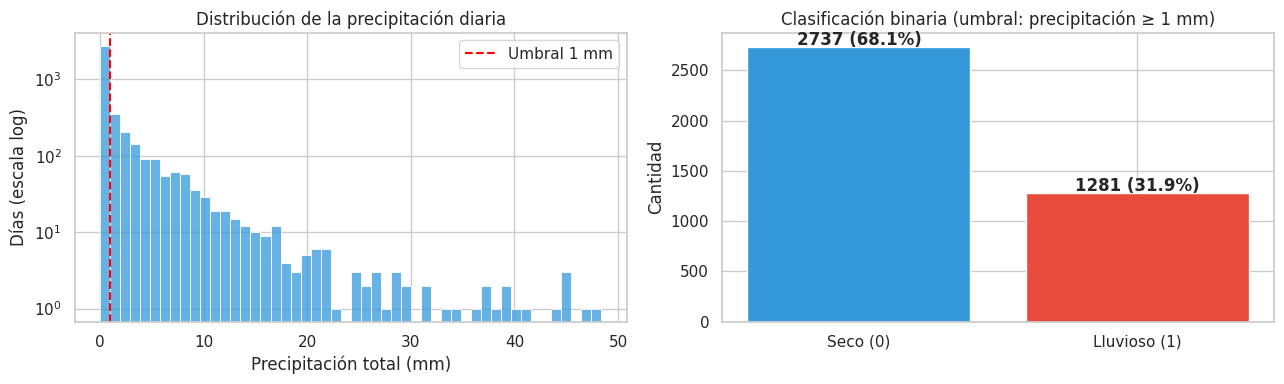


Ratio de desbalance: 2.1:1 (Seco vs Lluvioso)


In [3]:
# Distribución de la precipitación diaria
print('Precipitación total diaria (mm):')
print(df['precipMM'].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histograma original
sns.histplot(df['precipMM'], bins=50, ax=axes[0], color='#3498db')
axes[0].axvline(x=1, color='red', linestyle='--', label='Umbral 1 mm')
axes[0].set_yscale('log')
axes[0].set_title('Distribución de la precipitación diaria')
axes[0].set_xlabel('Precipitación total (mm)')
axes[0].set_ylabel('Días (escala log)')
axes[0].legend()

# Binarización
df['llueve'] = (df['precipMM'] >= 1).astype(int)

counts = df['llueve'].value_counts()
axes[1].bar(['Seco (0)', 'Lluvioso (1)'], counts.values,
            color=['#3498db', '#e74c3c'])
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 20, f'{v} ({v/len(df)*100:.1f}%)', ha='center', fontweight='bold')
axes[1].set_title('Clasificación binaria (umbral: precipitación ≥ 1 mm)')
axes[1].set_ylabel('Cantidad')

plt.tight_layout()
plt.show()

print(f'\nRatio de desbalance: {counts[0]/counts[1]:.1f}:1 (Seco vs Lluvioso)')

---
## 3. Análisis exploratorio orientado a clasificación

In [4]:
# 3.1  Estadísticas descriptivas por clase
features = df.columns.drop(['precipMM', 'llueve'])

comparison = df.groupby('llueve')[features].mean().T
comparison.columns = ['Seco (0)', 'Lluvioso (1)']
comparison['Diferencia %'] = ((comparison['Lluvioso (1)'] - comparison['Seco (0)']) / comparison['Seco (0)'] * 100).round(1)
comparison.style.background_gradient(subset=['Diferencia %'], cmap='RdYlGn')

,Seco (0),Lluvioso (1),Diferencia %
maxtempC,30.134088,28.603435,-5.100000
mintempC,18.828645,20.422326,8.500000
sunHour,10.914651,10.095472,-7.500000
uvIndex,6.015711,5.654176,-6.000000
humidity,59.993303,75.369243,25.600000
cloudcover,26.321977,53.063396,101.600000
pressure,1011.104615,1009.378111,-0.200000
DewPointC,14.726018,18.990211,29.000000
windspeedKmph,12.549448,12.234348,-2.500000
WindGustKmph,17.513975,17.065589,-2.600000


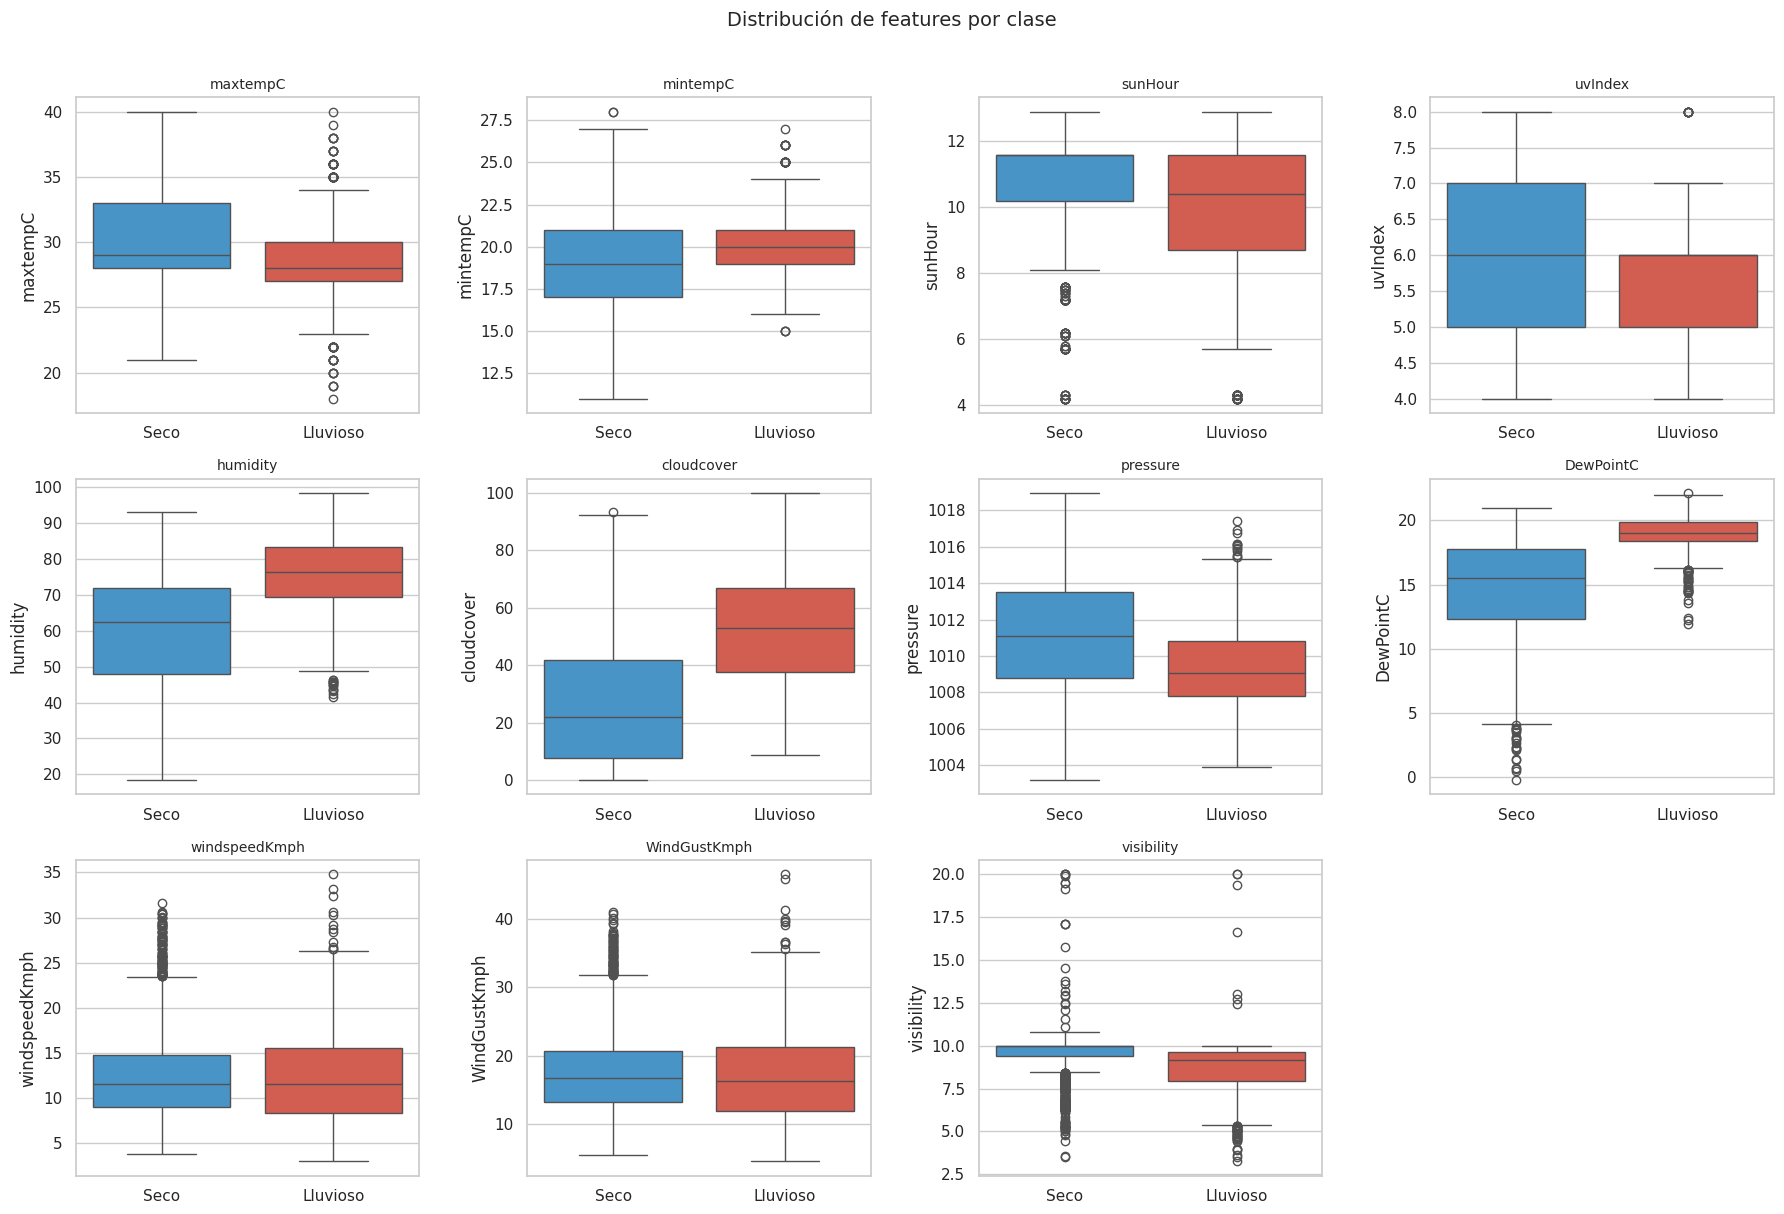

In [5]:
# 3.2  Distribución de features por clase (boxplots)
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(data=df, x='llueve', y=col, ax=axes[i],
                palette=['#3498db', '#e74c3c'], hue='llueve', legend=False)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('')
    axes[i].set_xticklabels(['Seco', 'Lluvioso'])

# Ocultar subplot vacío
axes[-1].set_visible(False)
fig.suptitle('Distribución de features por clase', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

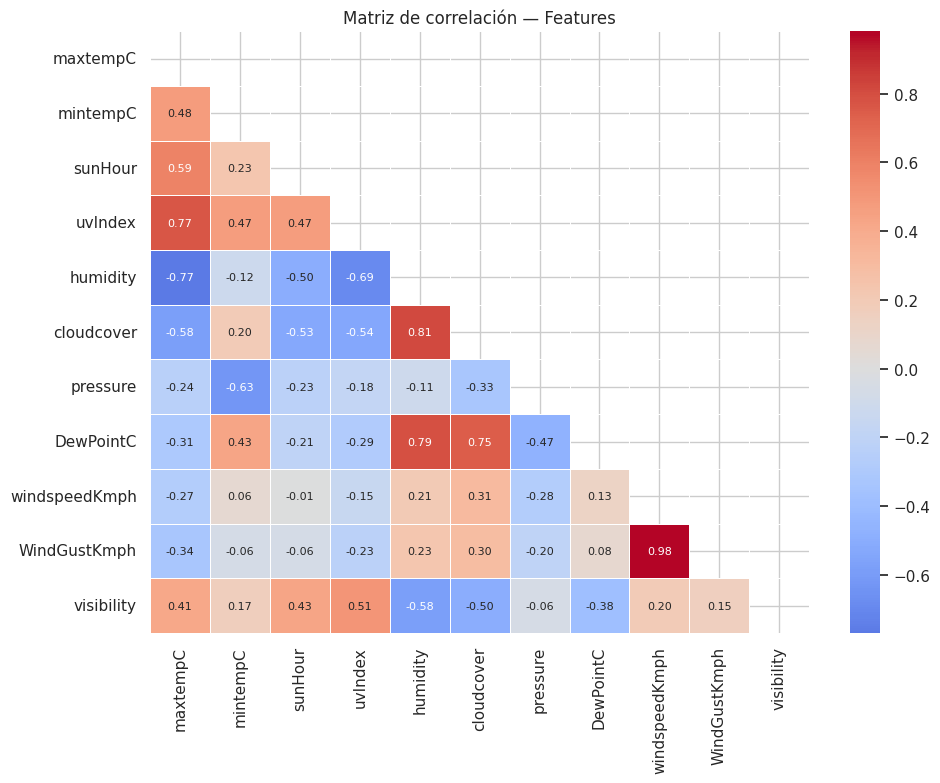

In [6]:
# 3.3  Correlación entre features
plt.figure(figsize=(10, 8))
corr = df[features].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, annot_kws={'size': 8})
plt.title('Matriz de correlación — Features')
plt.tight_layout()
plt.show()

---
## 4. Preparación de datos

In [7]:
# 4.1  Separación features / target
X = df[features].copy()
y = df['llueve'].copy()

# 4.2  Split estratificado 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f'Train: {X_train.shape[0]} muestras  |  Test: {X_test.shape[0]} muestras')
print(f'Proporción clase 1 en train: {y_train.mean():.3f}')
print(f'Proporción clase 1 en test:  {y_test.mean():.3f}')

Train: 3214 muestras  |  Test: 804 muestras
Proporción clase 1 en train: 0.319
Proporción clase 1 en test:  0.318


In [8]:
# 4.3  Verificación de escalas (justifica la estandarización)
print('Rangos de las features (train):')
print('='*50)
for col in features:
    mn, mx = X_train[col].min(), X_train[col].max()
    print(f'{col:30s}  [{mn:8.2f}, {mx:8.2f}]  rango: {mx-mn:.2f}')

print('\n→ Las escalas difieren significativamente entre features.')
print('  Esto afecta directamente a SVM y KNN (basados en distancias).')
print('  Logistic Regression también se beneficia de la estandarización.')

Rangos de las features (train):
maxtempC                        [   18.00,    40.00]  rango: 22.00
mintempC                        [   11.00,    28.00]  rango: 17.00
sunHour                         [    4.20,    12.90]  rango: 8.70
uvIndex                         [    4.00,     8.00]  rango: 4.00
humidity                        [   20.29,    98.25]  rango: 77.96
cloudcover                      [    0.00,   100.00]  rango: 100.00
pressure                        [ 1003.17,  1018.96]  rango: 15.79
DewPointC                       [    0.50,    22.12]  rango: 21.62
windspeedKmph                   [    2.96,    34.79]  rango: 31.83
WindGustKmph                    [    4.50,    46.54]  rango: 42.04
visibility                      [    3.25,    20.00]  rango: 16.75

→ Las escalas difieren significativamente entre features.
  Esto afecta directamente a SVM y KNN (basados en distancias).
  Logistic Regression también se beneficia de la estandarización.


---
## 5. Modelo 1 — Regresión Logística

**Fundamento:** Modelo lineal que estima la probabilidad de pertenencia a una clase mediante la función sigmoide. Ideal como **baseline** por su interpretabilidad y eficiencia.

In [9]:
# 5.1  Pipeline con estandarización
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                               class_weight='balanced'))  # Compensar desbalance
])

# Validación cruzada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores_lr = cross_val_score(pipe_lr, X_train, y_train, cv=cv, scoring='f1')
print(f'Logistic Regression — F1 CV: {scores_lr.mean():.4f} ± {scores_lr.std():.4f}')

# Entrenamiento final
pipe_lr.fit(X_train, y_train)
y_pred_lr = pipe_lr.predict(X_test)

Logistic Regression — F1 CV: 0.7521 ± 0.0106


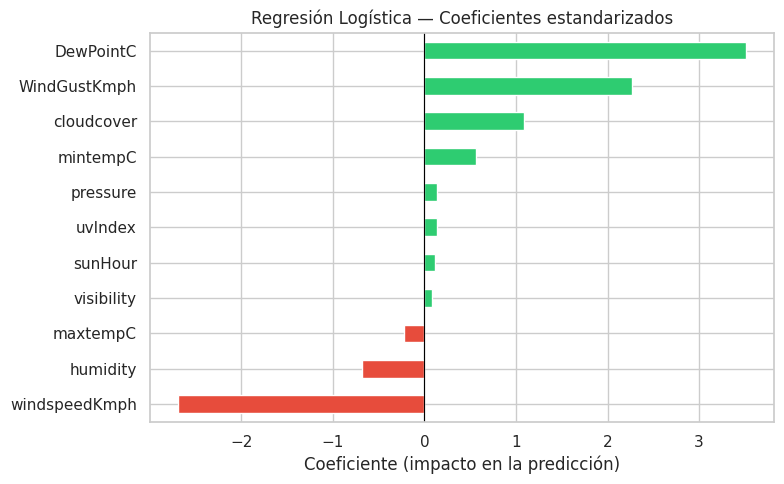


Interpretación: Un coeficiente positivo alto indica que valores mayores
de esa feature incrementan la probabilidad de clasificar como "Lluvioso".


In [10]:
# 5.2  Coeficientes del modelo (interpretabilidad)
coefs = pd.Series(
    pipe_lr.named_steps['clf'].coef_[0],
    index=features
).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#e74c3c' if c < 0 else '#2ecc71' for c in coefs.values]
coefs.plot(kind='barh', ax=ax, color=colors)
ax.set_title('Regresión Logística — Coeficientes estandarizados')
ax.set_xlabel('Coeficiente (impacto en la predicción)')
ax.axvline(x=0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

print('\nInterpretación: Un coeficiente positivo alto indica que valores mayores')
print('de esa feature incrementan la probabilidad de clasificar como "Lluvioso".')

---
## 6. Modelo 2 — Árbol de Decisión

**Fundamento:** Modelo no lineal que particiona el espacio de features mediante reglas if-else jerárquicas. Altamente interpretable, pero propenso al sobreajuste si no se controla la profundidad.

In [11]:
# 6.1  Pipeline (no requiere estandarización)
pipe_dt = Pipeline([
    ('clf', DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=10,
        class_weight='balanced', random_state=RANDOM_STATE
    ))
])

scores_dt = cross_val_score(pipe_dt, X_train, y_train, cv=cv, scoring='f1')
print(f'Decision Tree — F1 CV: {scores_dt.mean():.4f} ± {scores_dt.std():.4f}')

pipe_dt.fit(X_train, y_train)
y_pred_dt = pipe_dt.predict(X_test)

Decision Tree — F1 CV: 0.7854 ± 0.0105


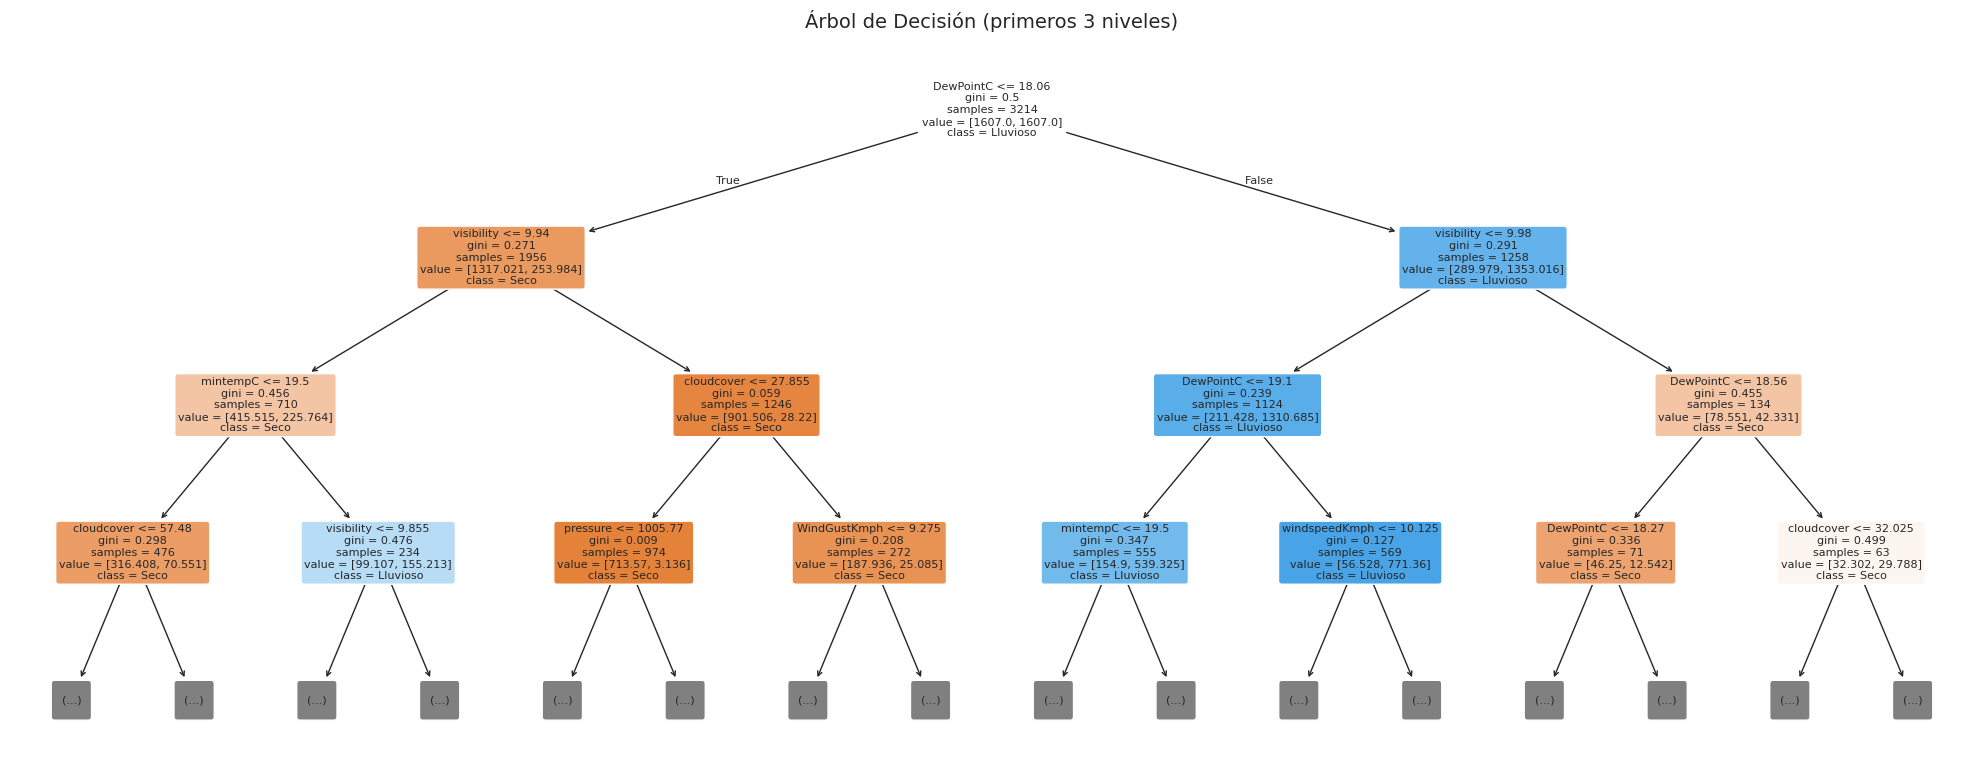

In [12]:
# 6.2  Visualización del árbol
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(
    pipe_dt.named_steps['clf'],
    feature_names=list(features),
    class_names=['Seco', 'Lluvioso'],
    filled=True, rounded=True, fontsize=8, ax=ax,
    max_depth=3  # Mostrar solo 3 niveles para legibilidad
)
ax.set_title('Árbol de Decisión (primeros 3 niveles)', fontsize=14)
plt.tight_layout()
plt.show()

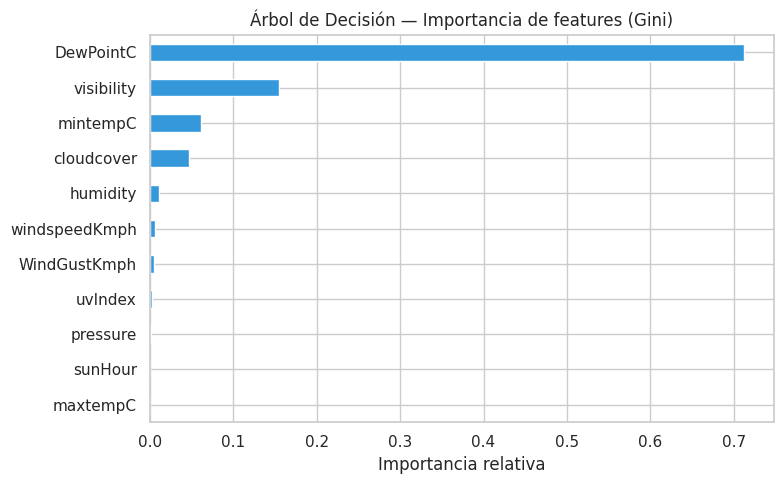

In [13]:
# 6.3  Importancia de features (Gini importance)
importances = pd.Series(
    pipe_dt.named_steps['clf'].feature_importances_,
    index=features
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind='barh', ax=ax, color='#3498db')
ax.set_title('Árbol de Decisión — Importancia de features (Gini)')
ax.set_xlabel('Importancia relativa')
plt.tight_layout()
plt.show()

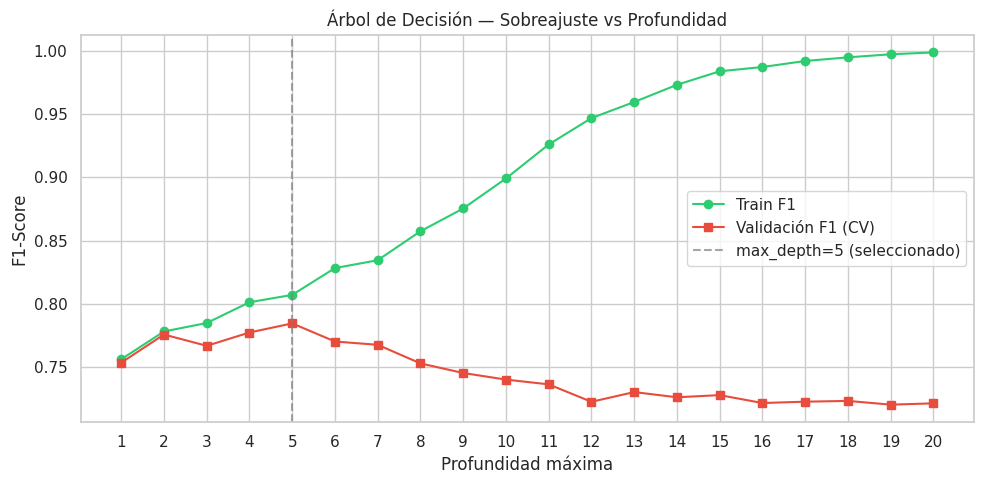

Observación: cuando la brecha entre train y validación crece,
el modelo está sobreajustando (memorizando el train set).


In [14]:
# 6.4  Efecto de la profundidad en sobreajuste/subajuste
depths = range(1, 21)
train_scores = []
val_scores = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, class_weight='balanced',
                                 random_state=RANDOM_STATE)
    dt.fit(X_train, y_train)
    train_scores.append(f1_score(y_train, dt.predict(X_train)))
    cv_s = cross_val_score(dt, X_train, y_train, cv=cv, scoring='f1')
    val_scores.append(cv_s.mean())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(depths, train_scores, 'o-', label='Train F1', color='#2ecc71')
ax.plot(depths, val_scores, 's-', label='Validación F1 (CV)', color='#e74c3c')
ax.axvline(x=5, color='gray', linestyle='--', alpha=0.7, label='max_depth=5 (seleccionado)')
ax.set_xlabel('Profundidad máxima')
ax.set_ylabel('F1-Score')
ax.set_title('Árbol de Decisión — Sobreajuste vs Profundidad')
ax.legend()
ax.set_xticks(depths)
plt.tight_layout()
plt.show()

print('Observación: cuando la brecha entre train y validación crece,')
print('el modelo está sobreajustando (memorizando el train set).')

---
## 7. Modelo 3 — Support Vector Machine (SVM)

**Fundamento:** Busca el hiperplano que maximiza el margen de separación entre clases. Con funciones kernel puede manejar fronteras no lineales. Es **sensible a la escala** de las features.

In [15]:
# 7.1  Comparación de kernels
kernels = ['linear', 'rbf', 'poly']
svm_results = {}

for kernel in kernels:
    pipe_svm = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel=kernel, class_weight='balanced',
                     random_state=RANDOM_STATE, probability=True))
    ])
    scores = cross_val_score(pipe_svm, X_train, y_train, cv=cv, scoring='f1')
    svm_results[kernel] = scores
    print(f'SVM ({kernel:6s}) — F1 CV: {scores.mean():.4f} ± {scores.std():.4f}')

# Seleccionar el mejor kernel
best_kernel = max(svm_results, key=lambda k: svm_results[k].mean())
print(f'\nMejor kernel: {best_kernel}')

SVM (linear) — F1 CV: 0.7499 ± 0.0115


SVM (rbf   ) — F1 CV: 0.7771 ± 0.0095


SVM (poly  ) — F1 CV: 0.7532 ± 0.0165

Mejor kernel: rbf


In [16]:
# 7.2  Entrenamiento con el mejor kernel
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel=best_kernel, class_weight='balanced',
                 random_state=RANDOM_STATE, probability=True))
])

pipe_svm.fit(X_train, y_train)
y_pred_svm = pipe_svm.predict(X_test)
scores_svm = svm_results[best_kernel]

In [17]:
# 7.3  Impacto de la estandarización en SVM
# SVM SIN estandarizar
svm_no_scale = SVC(kernel=best_kernel, class_weight='balanced',
                    random_state=RANDOM_STATE)
scores_no_scale = cross_val_score(svm_no_scale, X_train, y_train, cv=cv, scoring='f1')

print('Impacto de la estandarización en SVM:')
print(f'  CON StandardScaler: F1 = {scores_svm.mean():.4f}')
print(f'  SIN StandardScaler: F1 = {scores_no_scale.mean():.4f}')
print(f'  Diferencia: {(scores_svm.mean() - scores_no_scale.mean())*100:+.2f} puntos porcentuales')
print('\n→ La estandarización es CRÍTICA para modelos basados en distancias.')

Impacto de la estandarización en SVM:
  CON StandardScaler: F1 = 0.7771
  SIN StandardScaler: F1 = 0.6451
  Diferencia: +13.20 puntos porcentuales

→ La estandarización es CRÍTICA para modelos basados en distancias.


---
## 8. Modelo 4 — K-Nearest Neighbors (KNN)

**Fundamento:** Clasifica según la mayoría de votos de los K vecinos más cercanos. No paramétrico, sensible a la escala y a la dimensionalidad. El valor de K controla el trade-off bias-varianza.

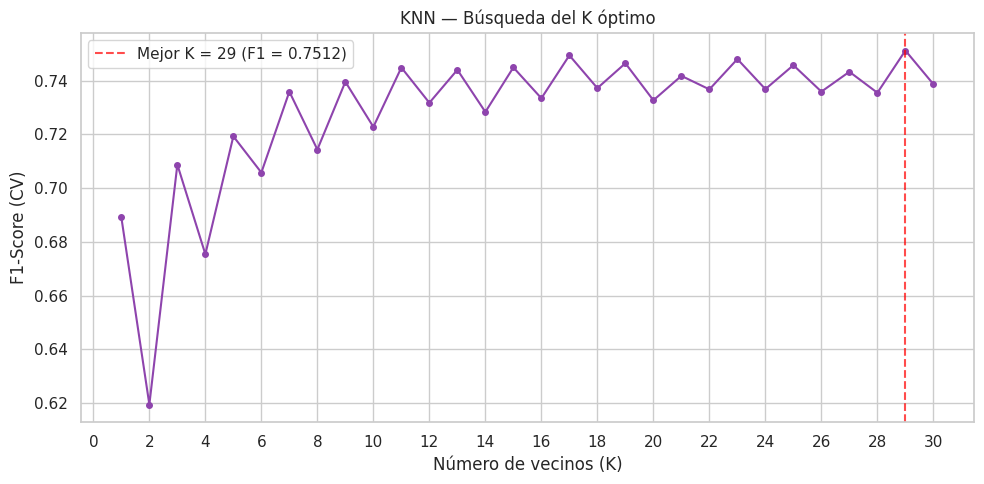

K óptimo: 29


In [18]:
# 8.1  Búsqueda del K óptimo
k_range = range(1, 31)
k_scores = []

for k in k_range:
    pipe_knn = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=k))
    ])
    scores = cross_val_score(pipe_knn, X_train, y_train, cv=cv, scoring='f1')
    k_scores.append(scores.mean())

best_k = k_range[np.argmax(k_scores)]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_range, k_scores, 'o-', markersize=4, color='#8e44ad')
ax.axvline(x=best_k, color='red', linestyle='--', alpha=0.7,
           label=f'Mejor K = {best_k} (F1 = {max(k_scores):.4f})')
ax.set_xlabel('Número de vecinos (K)')
ax.set_ylabel('F1-Score (CV)')
ax.set_title('KNN — Búsqueda del K óptimo')
ax.legend()
ax.set_xticks(range(0, 31, 2))
plt.tight_layout()
plt.show()

print(f'K óptimo: {best_k}')

In [19]:
# 8.2  Entrenamiento con K óptimo
pipe_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', KNeighborsClassifier(n_neighbors=best_k))
])

scores_knn = cross_val_score(pipe_knn, X_train, y_train, cv=cv, scoring='f1')
print(f'KNN (K={best_k}) — F1 CV: {scores_knn.mean():.4f} ± {scores_knn.std():.4f}')

pipe_knn.fit(X_train, y_train)
y_pred_knn = pipe_knn.predict(X_test)

KNN (K=29) — F1 CV: 0.7512 ± 0.0137


---
## 9. Análisis comparativo de modelos

In [20]:
# 9.1  Tabla resumen
models = {
    'Logistic Regression': (pipe_lr, y_pred_lr, scores_lr),
    'Decision Tree':       (pipe_dt, y_pred_dt, scores_dt),
    f'SVM ({best_kernel})': (pipe_svm, y_pred_svm, scores_svm),
    f'KNN (K={best_k})':   (pipe_knn, y_pred_knn, scores_knn)
}

summary = []
for name, (pipe, y_pred, cv_scores) in models.items():
    summary.append({
        'Modelo': name,
        'F1 CV (mean)': f'{cv_scores.mean():.4f}',
        'F1 CV (std)': f'{cv_scores.std():.4f}',
        'Accuracy Test': f'{accuracy_score(y_test, y_pred):.4f}',
        'F1 Test': f'{f1_score(y_test, y_pred):.4f}'
    })

summary_df = pd.DataFrame(summary)
print('='*80)
print('COMPARACIÓN DE MODELOS')
print('='*80)
summary_df

COMPARACIÓN DE MODELOS


,Modelo,F1 CV (mean),F1 CV (std),Accuracy Test,F1 Test
0,Logistic Regression,0.7521,0.0106,0.8147,0.7444
1,Decision Tree,0.7854,0.0105,0.8308,0.7733
2,SVM (rbf),0.7771,0.0095,0.8259,0.7651
3,KNN (K=29),0.7512,0.0137,0.8122,0.6986


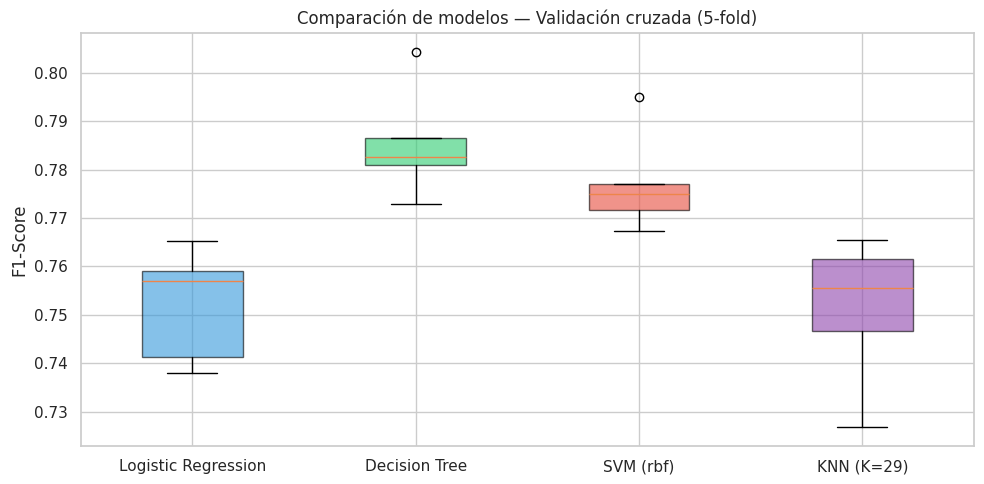

In [21]:
# 9.2  Boxplot comparativo de validación cruzada
fig, ax = plt.subplots(figsize=(10, 5))
cv_data = [scores_lr, scores_dt, scores_svm, scores_knn]
labels = list(models.keys())
bp = ax.boxplot(cv_data, tick_labels=labels, patch_artist=True)
colors_box = ['#3498db', '#2ecc71', '#e74c3c', '#8e44ad']
for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
ax.set_ylabel('F1-Score')
ax.set_title('Comparación de modelos — Validación cruzada (5-fold)')
plt.tight_layout()
plt.show()

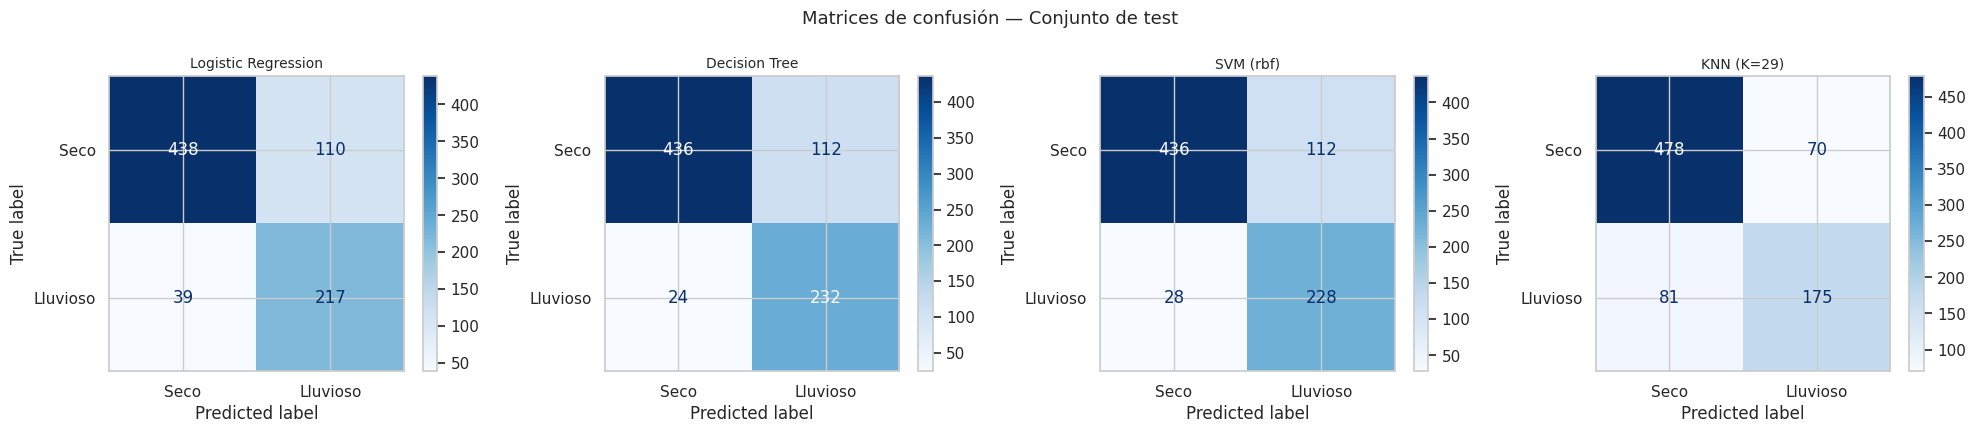

In [22]:
# 9.3  Matrices de confusión comparativas
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for ax, (name, (pipe, y_pred, _)) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=['Seco', 'Lluvioso'],
        cmap='Blues', ax=ax
    )
    ax.set_title(name, fontsize=10)

fig.suptitle('Matrices de confusión — Conjunto de test', fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

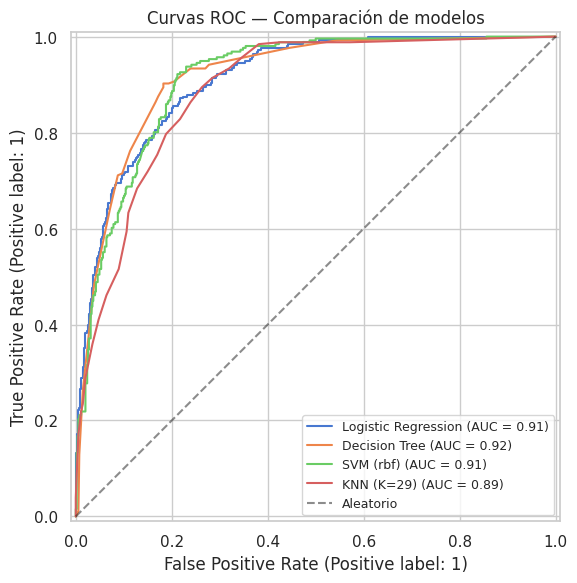

In [23]:
# 9.4  Curvas ROC comparativas
fig, ax = plt.subplots(figsize=(7, 6))

for name, (pipe, _, _) in models.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=ax, name=name)

ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aleatorio')
ax.set_title('Curvas ROC — Comparación de modelos')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

In [24]:
# 9.5  Classification report detallado del mejor modelo
best_model_name = max(models, key=lambda k: float(models[k][2].mean()))
best_pipe, best_pred, best_cv = models[best_model_name]

print(f'\nMejor modelo: {best_model_name}')
print('='*60)
print(classification_report(y_test, best_pred,
                             target_names=['Seco', 'Lluvioso']))


Mejor modelo: Decision Tree
              precision    recall  f1-score   support

        Seco       0.95      0.80      0.87       548
    Lluvioso       0.67      0.91      0.77       256

    accuracy                           0.83       804
   macro avg       0.81      0.85      0.82       804
weighted avg       0.86      0.83      0.84       804



---
## 10. Resumen comparativo (teórico)

| Modelo | Fortalezas | Limitaciones | ¿Cuándo usarlo? |
|---|---|---|---|
| **Regresión Logística** | Rápido, interpretable (coeficientes), probabilístico | Asume relación lineal entre features y log-odds | Baseline; cuando la interpretabilidad es prioritaria |
| **Árbol de Decisión** | Interpretable (visualización), maneja no linealidades, no requiere estandarización | Propenso a sobreajuste; inestable (pequeños cambios en datos alteran el árbol) | Cuando se necesitan reglas explicables; como parte de ensambles |
| **SVM** | Efectivo en alta dimensionalidad; flexible con kernels | Sensible a la escala; costoso en datasets grandes; difícil de interpretar | Datasets de tamaño moderado con fronteras complejas |
| **KNN** | Simple, no paramétrico, adaptable | Lento en predicción (distancias contra todo el train); sensible a escala y dimensionalidad | Datasets pequeños-medianos; cuando la frontera es irregular |

---
## 11. conclusiones

- Los días lluviosos tienen **mucha más nubosidad** (`cloudcover` +101.6 %), **punto de rocío más alto** (`DewPointC` +29.0 %) y **más humedad** (+25.6 %). También tienen menos horas de sol, menos visibilidad y una temperatura máxima algo menor. Esto tiene sentido físico: para que llueva se necesita aire húmedo y nubes.
- Hay features muy redundantes: `windspeedKmph`–`WindGustKmph` (r = 0.98), `humidity`–`cloudcover` (0.81) y `humidity`–`DewPointC` (0.79).

**Comparación de modelos**

| Modelo | F1 CV | F1 test | Accuracy test | Recall "Lluvioso" | Precisión "Lluvioso" | AUC |
|---|---|---|---|---|---|---|
| Regresión Logística | 0.7521 ± 0.0106 | 0.7444 | 0.8147 | 0.85 | 0.66 | 0.91 |
| **Árbol de Decisión** (max_depth=5) | **0.7854** ± 0.0105 | **0.7733** | **0.8308** | **0.91** | 0.67 | **0.92** |
| SVM (rbf) | 0.7771 ± 0.0095 | 0.7651 | 0.8259 | 0.89 | 0.67 | 0.91 |
| KNN (K=29) | 0.7512 ± 0.0137 | 0.6986 | 0.8122 | 0.68 | **0.71** | 0.89 |

**Hallazgos**
1. **El Árbol de Decisión es el mejor modelo** y el SVM rbf queda muy cerca (la diferencia de 0.8 puntos en F1 CV es menor que una desviación estándar, así que en la práctica están empatados). El árbol funciona bien porque **una sola variable resuelve casi todo el problema**: el punto de rocío (`DewPointC`) concentra el 71 % de la importancia y la visibilidad el 15 %. El primer corte del árbol es `DewPointC <= 18.06 °C` y el segundo nivel corta por `visibility` ≈ 9.9 km. Unos pocos umbrales sobre esas variables separan bien los días secos de los lluviosos, algo ideal para un árbol.
2. **La profundidad 5 fue una buena elección:** el F1 de validación llega a su máximo en profundidad 5 (≈ 0.78) y luego baja hasta ≈ 0.72, mientras el F1 de entrenamiento sube hasta 0.999, un sobreajuste claro.
3. **SVM:** el kernel rbf (0.777) supera al lineal (0.750) y al polinómico (0.753), lo que indica que la frontera es algo no lineal. **Sin estandarizar, el F1 cae 13.2 puntos** (0.777 → 0.645), porque `pressure` (~1010) y `cloudcover` (0–100) dominarían las distancias.
4. **KNN es el más débil en F1** porque, a diferencia de los otros tres, el pipeline de la sesión no le compensa el desbalance (`KNeighborsClassifier` no tiene `class_weight`). Por eso es el más "conservador": tiene la mejor precisión (0.71), pero deja pasar 81 de los 256 días lluviosos del test (el árbol solo 24). El K óptimo (29) está en el borde del rango probado, aunque la curva es casi plana desde K ≈ 17, así que un K mayor no mejoraría mucho. Los K impares salen mejor que los pares porque, con 2 clases, un K impar evita empates en la votación.
5. **Los coeficientes de la Regresión Logística deben leerse con cuidado.** `DewPointC` es el coeficiente positivo más fuerte (+3.5), coherente con el EDA. Pero `windspeedKmph` (−2.7) y `WindGustKmph` (+2.3) tienen signos opuestos aunque su correlación es 0.98: por la **multicolinealidad**, el modelo usa su diferencia (una posible interpretación son las ráfagas por encima del viento medio, típicas de tormentas). Del mismo modo, `humidity` sale negativo (−0.7) aunque los días lluviosos son más húmedos, porque su efecto ya lo capturan `DewPointC` y `cloudcover`.
6. **Frente al dataset de vinos de la sesión**, todos los modelos rinden mucho mejor aquí (F1 ≈ 0.75–0.79 frente a ≈ 0.50–0.54): las clases están mejor separadas por variables con sentido físico y el desbalance es menor (2.1:1 frente a 6.4:1).

**Limitaciones**
- El modelo es **diagnóstico, no de pronóstico**: usa las condiciones del mismo día (nubosidad, visibilidad), que se miden mientras llueve. Para predecir si lloverá **mañana**, habría que desplazar la variable objetivo un día.
- El split aleatorio ignora el orden temporal y la estacionalidad (monzón). Una validación temporal (entrenar con años anteriores y probar con los más recientes) sería más realista.

---
*Ingeniería del Conocimiento (ISO56B) — UNCP — 2026-II*